# Does the Collins flood-damage map identify later reported floods?

**Local temporal validation · June 2020–December 2025 · run 2026-10-15**

The frozen map retains a **moderate ranking signal**: AUC **0.696** for all later flood-report cells and **0.683** for cells with recorded damage or casualties. The highest-scoring 20% of eligible area within each watershed captures about **45%** of all report cells.

This is a **presence/background ranking check**, not validation of calibrated annual probabilities. Backgrounds match watersheds, but not the paper's land-cover and floodplain sampling rules. The results therefore cannot be directly compared with the paper's reported AUC of 0.750.

The notebook is executed and includes its outputs. It reads the small archived result files beside it; the full scoring workflow is in [`../validate_fdp.py`](../validate_fdp.py).

In [1]:
import hashlib
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

BASE = Path.cwd()
if not (BASE / 'metrics.json').exists():
    BASE = BASE / 'input-data/tensor/fdp/validation-2026-10-15'
assert (BASE / 'metrics.json').exists(), (
    "Run from the repository root or this notebook's directory."
)
ROOT = BASE.parents[3]
metrics = json.loads((BASE / 'metrics.json').read_text())
manifest = json.loads((BASE / 'manifest.json').read_text())
groups = pd.read_csv(BASE / 'metrics_by_group.csv', dtype={'group': str})
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 80)

## What was evaluated?

- **Surface:** the project's archived USGS Collins TIFF, sampled directly on its native EPSG:5070, 100 m grid. Twelve sampled cells match the served Zarr level 0 exactly.
- **Reports:** NOAA `Flood` and `Flash Flood`, beginning June 2020 through December 2025; Alaska, Hawaii and territories excluded. Begin coordinates are the primary location policy.
- **Primary unit:** one presence per unique 100 m cell. Repeated events in the same cell do not multiply that cell's weight.
- **Recorded-impact sensitivity:** positive property/crop damage, or at least one injury/death. Missing damage amounts remain unknown. This does not recover unquantified disruption or narrative-only impacts.
- **Background:** uniform valid raster cells within the same HUC-2 watersheds, excluding known historical and test-period report cells. Background is reweighted to match the positive cohort's watershed distribution.

All-report positives include events without recorded damage. Background cells are not verified non-flooded locations.

In [2]:
sample = pd.DataFrame(
    {
        'Step': [
            'All NOAA Flood / Flash Flood event rows',
            'CONUS event rows',
            'Valid begin-point event rows',
            'Unique begin-point cells',
            'Recorded-impact unique cells',
            'Background cells',
        ],
        'Count': [
            metrics['raw_events_in_test_period'],
            metrics['raw_conus_events_in_test_period'],
            metrics['valid_test_events'],
            metrics['all_reports_unique_cells']['n_positive'],
            metrics['recorded_impact_unique_cells']['n_positive'],
            metrics['all_reports_unique_cells']['n_background'],
        ],
    }
)
display(sample.style.hide(axis='index').format({'Count': '{:,}'}))

Step,Count
All NOAA Flood / Flash Flood event rows,"36,654"
CONUS event rows,"35,095"
Valid begin-point event rows,"34,627"
Unique begin-point cells,"32,091"
Recorded-impact unique cells,"8,642"
Background cells,"227,020"


Of the 35,095 CONUS events, **468 begin locations had no valid raster value** and were excluded. The remaining 34,627 events occupy 32,091 unique cells. There were 8,887 retained events with recorded impacts, occupying 8,642 unique cells.

Current HUC-2 boundaries were simplified to 100 m. Ambiguous polygon-overlap strips were excluded rather than duplicated; no test-period begin report was excluded for that reason.

## Headline results

AUC measures how often a reported location outranks a background location (with half-credit for score ties). AUC 0.5 represents no discrimination under this evaluation design.

Intervals below use **200 Poisson bootstrap replicates of 50 km spatial blocks**. They reflect sampling variability conditional on this method, not uncertainty from reporting bias or background selection. Only one background-generation seed was used.

In [3]:
rows = []
for label, key in [
    ('All flood reports', 'all_reports_unique_cells'),
    ('Recorded damage / casualties', 'recorded_impact_unique_cells'),
]:
    m = metrics[key]
    lo, hi = m['auc_95ci_50km_block_poisson']
    rows.append(
        {
            'Cohort': label,
            'Cells': m['n_positive'],
            'ROC AUC': m['auc'],
            'Approx. 95% interval': f'{lo:.3f}–{hi:.3f}',
            'Recall in top 10% area': m['recall_top10_huc_area'],
            'Recall in top 20% area': m['recall_top20_huc_area'],
        }
    )
display(
    pd.DataFrame(rows)
    .style.hide(axis='index')
    .format(
        {
            'Cells': '{:,}',
            'ROC AUC': '{:.3f}',
            'Recall in top 10% area': '{:.1%}',
            'Recall in top 20% area': '{:.1%}',
        }
    )
)

Cohort,Cells,ROC AUC,Approx. 95% interval,Recall in top 10% area,Recall in top 20% area
All flood reports,"32,091",0.696,0.689–0.703,24.0%,45.0%
Recorded damage / casualties,"8,642",0.683,0.674–0.692,22.8%,42.6%


The top-area metric selects the highest-scoring fraction **within each watershed**. Large groups of cells tie at score 1.0, so boundary ties are allocated fractionally: expected recall under uniform random tie-breaking. Including every tied cell would overstate capture at a fixed area budget.

The archived JSON also contains average precision, computed with an artificial **50:50 total positive/background weight**. It is not population precision or the probability a building will suffer damage.

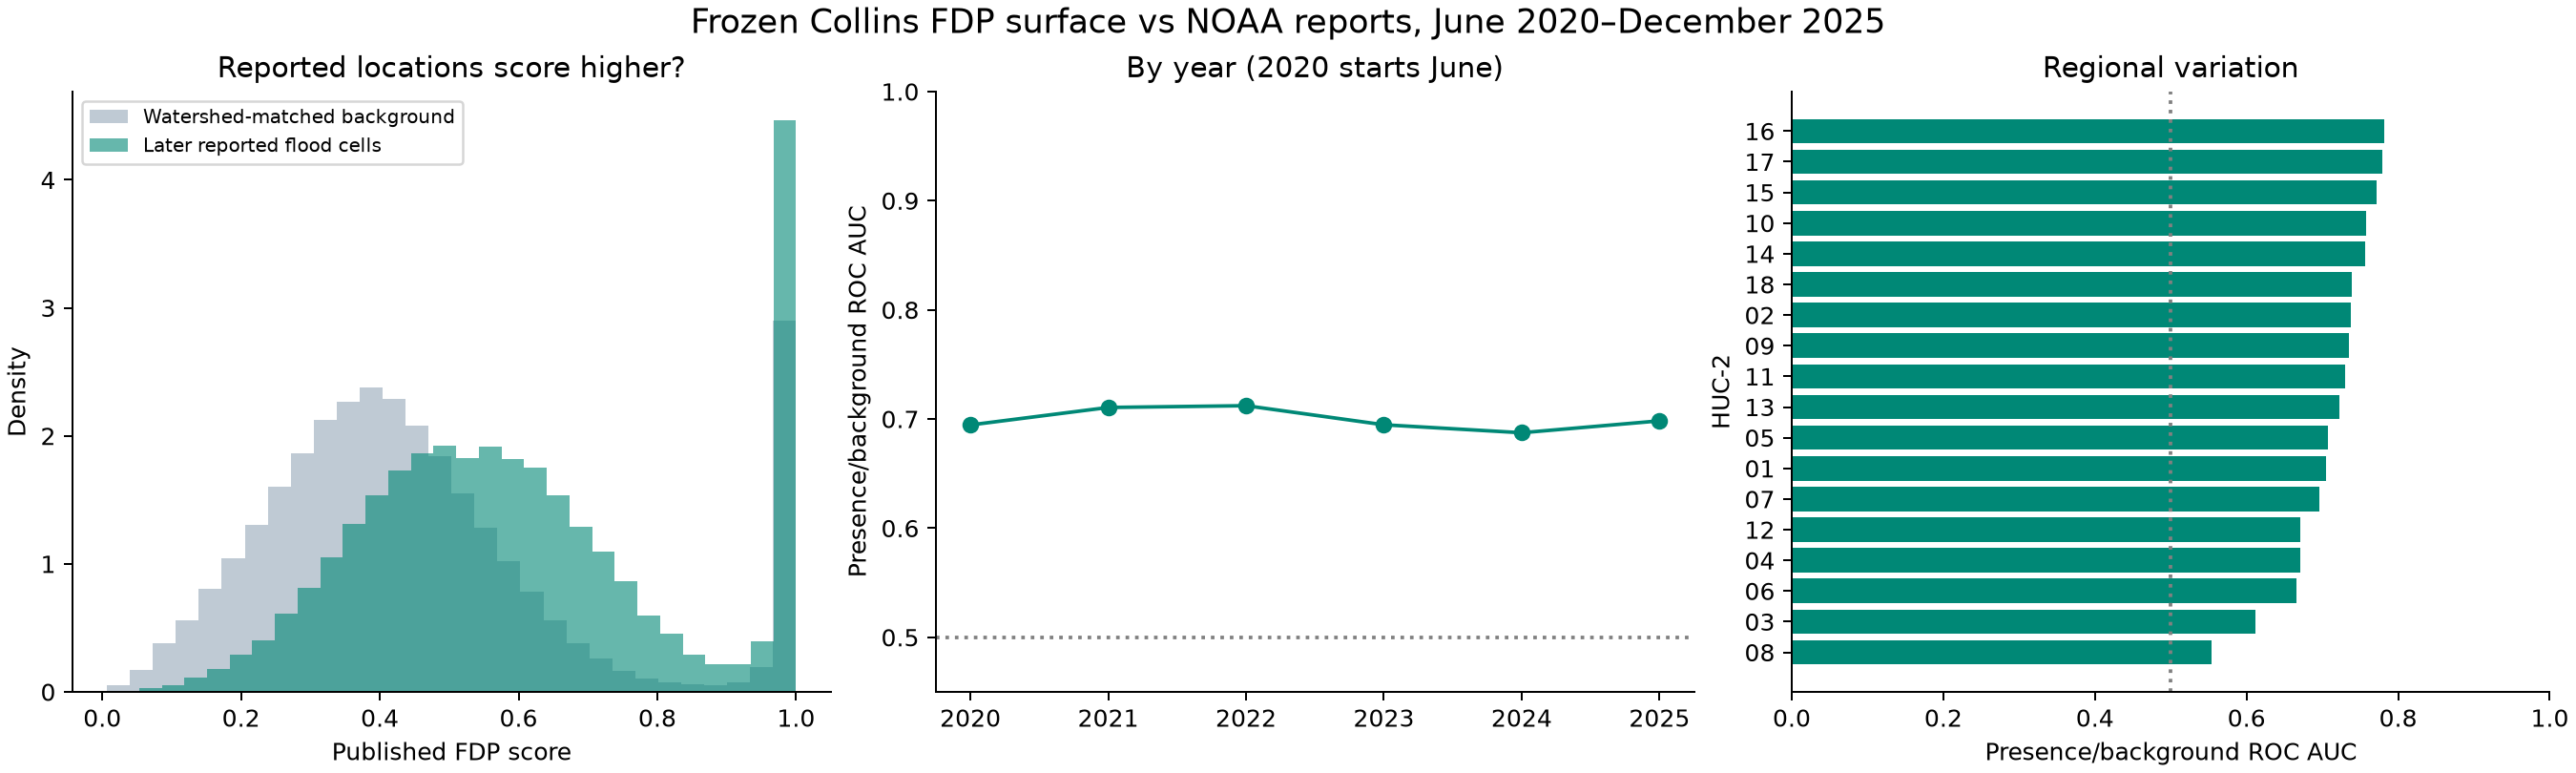

In [4]:
display(Image(filename=str(BASE / 'validation.png')))

## Where does the map struggle?

The all-report AUC is **0.740 for Flood**, versus **0.677 for Flash Flood**. Lower Mississippi (HUC 08) is near chance under this background definition; South Atlantic-Gulf (HUC 03) is also weaker than the national result. These are priorities for reviewing missed reports and selecting retraining pilots.

Yearly AUCs lie between 0.687 and 0.712, with no clear monotonic deterioration. That is a descriptive observation, not a formal trend test. The 2020 evaluation starts in June.

In [5]:
names = {
    '01': 'New England',
    '02': 'Mid Atlantic',
    '03': 'South Atlantic-Gulf',
    '04': 'Great Lakes',
    '05': 'Ohio',
    '06': 'Tennessee',
    '07': 'Upper Mississippi',
    '08': 'Lower Mississippi',
    '09': 'Souris-Red-Rainy',
    '10': 'Missouri',
    '11': 'Arkansas-White-Red',
    '12': 'Texas-Gulf',
    '13': 'Rio Grande',
    '14': 'Upper Colorado',
    '15': 'Lower Colorado',
    '16': 'Great Basin',
    '17': 'Pacific Northwest',
    '18': 'California',
}
huc = groups[groups.grouping == 'huc2'].copy()
huc['Watershed'] = huc.group.map(names)
huc = huc.sort_values('auc')[['group', 'Watershed', 'n_positive', 'auc', 'recall_top20_huc_area']]
huc.columns = ['HUC-2', 'Watershed', 'Report cells', 'ROC AUC', 'Recall in top 20% area']
display(
    huc.style.hide(axis='index').format(
        {'Report cells': '{:,}', 'ROC AUC': '{:.3f}', 'Recall in top 20% area': '{:.1%}'}
    )
)

HUC-2,Watershed,Report cells,ROC AUC,Recall in top 20% area
08,Lower Mississippi,"1,499",0.554,17.0%
03,South Atlantic-Gulf,"4,542",0.612,19.2%
06,Tennessee,933,0.665,43.4%
04,Great Lakes,777,0.671,38.0%
12,Texas-Gulf,"1,937",0.671,39.9%
07,Upper Mississippi,"1,395",0.696,45.4%
01,New England,"1,390",0.705,51.3%
05,Ohio,"4,910",0.707,49.1%
13,Rio Grande,481,0.723,50.4%
11,Arkansas-White-Red,"2,381",0.730,51.7%


These regional comparisons use **all reports**, not only the recorded-impact subset. Watershed sample sizes vary, and regional uncertainty intervals have not been estimated. The equal-HUC mean AUC is 0.711; the headline pooled AUC weights regions by their report distribution.

In [6]:
years = groups[groups.grouping == 'year'][
    ['group', 'n_positive', 'auc', 'recall_top20_huc_area']
].copy()
years.columns = ['Year', 'Unique cells within year', 'ROC AUC', 'Recall in top 20% area']
display(
    years.style.hide(axis='index').format(
        {
            'Unique cells within year': '{:,}',
            'ROC AUC': '{:.3f}',
            'Recall in top 20% area': '{:.1%}',
        }
    )
)

Year,Unique cells within year,ROC AUC,Recall in top 20% area
2020,"3,229",0.695,44.1%
2021,"6,393",0.711,47.6%
2022,"4,506",0.712,48.6%
2023,"5,843",0.695,45.4%
2024,"6,199",0.687,43.2%
2025,"6,942",0.698,45.1%


## Sensitivity to location and counting choices

The main result persists under alternative counting/location policies. Previously reported cells are much easier to rank than newly reported cells. This overlap is reconstructed using **current NOAA begin records**, not the unavailable original training-point archive.

NOAA's location table can contain multiple locations per event. Those are a sensitivity analysis, not additional independent damage observations.

In [7]:
scenarios = [
    ('Primary: unique begin cells', 'all_reports_unique_cells'),
    ('One observation per event', 'all_reports_event_weighted'),
    ('New cells vs historical begin reports', 'new_cells_vs_historical_begin'),
    ('Repeated historical cells', 'repeated_cells_vs_historical_begin'),
    ('All location-table points, unique cells', 'all_location_rows_unique_cells'),
    ('Location-table points with recorded impacts', 'all_location_rows_impact_unique_cells'),
]
sensitivity = pd.DataFrame(
    [
        {
            'Policy': label,
            'Observations': metrics[key]['n_positive'],
            'ROC AUC': metrics[key]['auc'],
        }
        for label, key in scenarios
    ]
)
display(sensitivity.style.hide(axis='index').format({'Observations': '{:,}', 'ROC AUC': '{:.3f}'}))

Policy,Observations,ROC AUC
Primary: unique begin cells,"32,091",0.696
One observation per event,"34,627",0.703
New cells vs historical begin reports,"30,362",0.688
Repeated historical cells,"1,729",0.829
"All location-table points, unique cells","102,888",0.683
Location-table points with recorded impacts,"26,780",0.669


## Limits on the conclusion

1. **This is not the paper's matched pseudo-absence evaluation.** Original USGS sampling layers could not be downloaded, and supplementary selection rules were not recovered. Land cover and floodplain membership are not controlled here. Differences from the paper's AUC cannot establish deterioration.
2. **Reporting and exposure remain confounded with hazard.** No reported flood is not evidence of no flood. Monetary estimates and locations have uncertainty; a 100 m output grid does not imply 100 m observational accuracy.
3. **This does not test building losses, annual probability or calibration.** It tests the rank of later reported locations relative to the selected backgrounds.
4. **Historical overlap is approximate.** The reconstructed historical sample has 71,526 unique cells, near but not identical to the paper's 71,434 locations. That numerical proximity is not proof of identical selection.
5. **2024–2025 has now been inspected.** It can support a transparent retrospective comparison, but is no longer an untouched confirmatory holdout for decisions informed by this work.

**Next step:** preserve this baseline, recover the original sampling inputs/rules, add an exposure-controlled evaluation, and pilot damage-only retraining in the weaker watersheds before a national rerun.

**Does this show a rebuild would improve the map?** No: only the frozen model was tested. It motivates a retraining experiment. Compare original-period and extended-period fits using the same predictors and modeling procedure on the same later years excluded from training, then fit the production model on all available reports.

## Compute and reproducibility

The completed cached-input run took **43 seconds wall time** with about **11.3 GB peak memory footprint**. The initial 3.17 GB TIFF download took roughly 6.2 minutes. All execution and artifact writes were local; no Coiled job was launched. Existing S3 read/egress charges may apply. These timings do not estimate model-training costs.

Small metrics, input hashes, package versions and the figure are archived alongside this notebook. Large scored/background Parquet files are under `_build/fdp-validation/2026-10-15/` (git-ignored), and raw inputs are in `~/.cache/ocr/fdp-validation`.

The next cell verifies that the archived results correspond to the current validation script, and shows the input inventory.

In [8]:
script = BASE.parent / 'validate_fdp.py'
script_hash = hashlib.sha256(script.read_bytes()).hexdigest()
assert script_hash == manifest['script_sha256'], (
    'Script changed since archived execution; inspect or rerun.'
)
assert metrics['source_vs_served_check']['max_absolute_difference'] == 0
inventory = pd.DataFrame(manifest['sources'])
inventory['File'] = inventory.path.map(lambda p: Path(p).name)
inventory['MB'] = inventory.bytes / 1e6
print(f'Script hash verified. {len(inventory)} source records; seed {manifest["seed"]}.')
print('12 sampled TIFF cells exactly match served Zarr level 0.')
display(inventory[['File', 'MB']].style.hide(axis='index').format({'MB': '{:,.2f}'}))

Script hash verified. 29 source records; seed 20261015.
12 sampled TIFF cells exactly match served Zarr level 0.


File,MB
StormEvents_details-ftp_v1.0_d2006_c20260323.csv.gz,7.59
StormEvents_details-ftp_v1.0_d2007_c20260323.csv.gz,9.78
StormEvents_details-ftp_v1.0_d2008_c20260323.csv.gz,12.28
StormEvents_details-ftp_v1.0_d2009_c20260323.csv.gz,10.34
StormEvents_details-ftp_v1.0_d2010_c20260323.csv.gz,11.73
StormEvents_details-ftp_v1.0_d2011_c20260323.csv.gz,15.70
StormEvents_details-ftp_v1.0_d2012_c20260323.csv.gz,11.82
StormEvents_details-ftp_v1.0_d2013_c20260323.csv.gz,11.73
StormEvents_details-ftp_v1.0_d2014_c20260323.csv.gz,11.08
StormEvents_details-ftp_v1.0_d2015_c20260323.csv.gz,10.04


### Rerun locally

The notebook itself only reads archived results. To rebuild scores and metrics from the cached source snapshot, use the runner from the repository root:

```bash
uv run input-data/tensor/fdp/validate_fdp.py --output _build/fdp-validation/2026-10-15
```

The script declares its dependencies. An existing environment with those packages also works; the original run used OCR's default Pixi environment. The minimal `fdp` packaging environment alone is insufficient. Rerunning writes fresh output into `_build`; it does **not** automatically overwrite this archived presentation.

Six focused scientific checks:

```bash
python -m unittest discover -s input-data/tensor/fdp -p test_validate_fdp.py
```

Source data: [NOAA bulk files](https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/), [NOAA field documentation](https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/Storm-Data-Bulk-csv-Format.pdf), [USGS HUC-2 service](https://hydro.nationalmap.gov/arcgis/rest/services/wbd/MapServer/1), [Collins release](https://doi.org/10.5066/P954TTQN). See [manifest.json](manifest.json) for exact URLs, file hashes and package versions, and [README.md](README.md) for the full run record.